# Day 18: Hallucination Understanding and Detection
**Goal:** measure how often an LLM fabricates facts with no context vs with RAG, categorise the failures, and build a 4-signal hallucination detector.

**Models (all local, no API key):** Qwen2.5-1.5B-Instruct (generator), all-MiniLM-L6-v2 (embeddings), FAISS (retrieval).

> Runtime: Colab, GPU T4 (Runtime > Change runtime type).

## Step 0: Install and imports

In [1]:
!pip install -q transformers accelerate sentence-transformers faiss-cpu pandas matplotlib

In [2]:
import re, json, torch, faiss, numpy as np, pandas as pd, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL)
llm = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float16, device_map="auto")
embedder = SentenceTransformer("all-MiniLM-L6-v2")

def chat(system, user, max_new_tokens=90):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(llm.device)
    out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
print("Models loaded")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (14 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Models loaded


## Step 1: Define the scoring criteria BEFORE scoring
Written first so we cannot bend the rules after seeing the answers.

| Label | Criteria |
|---|---|
| **correct** | The main fact matches the ground truth in meaning. Extra true detail is fine. |
| **partially correct** | The main fact is right but a supporting detail is wrong, vague or missing. |
| **hallucinated** | The main fact contradicts the ground truth, or the model invents specifics (names, numbers, dates) not supported by the truth. |

**Hallucination types (for hallucinated answers):**
1. **fabricated specific fact:** invented name, number, date, title
2. **outdated info as current:** was once true, stated as true now
3. **confident wrong answer:** wrong, stated with no hedging
4. **plausible but unverifiable:** sounds reasonable, cannot be checked against truth

## Step 2: The 20-question dataset (4 domains, ground truth known)
`key_facts` is a list of strings; if any appears in the answer we *suggest* a label, but you make the final call in Step 4.

In [3]:
questions = [
 # Science
 {"id":1,"domain":"Science","question":"What is the chemical symbol for gold?","ground_truth":"Au","key_facts":["au"]},
 {"id":2,"domain":"Science","question":"How many bones are in the adult human body?","ground_truth":"206","key_facts":["206"]},
 {"id":3,"domain":"Science","question":"What is the speed of light in vacuum in km/s (approximately)?","ground_truth":"about 299,792 km/s","key_facts":["299,792","299792","299,800","300,000"]},
 {"id":4,"domain":"Science","question":"Which planet in our solar system has the most known moons?","ground_truth":"Saturn","key_facts":["saturn"]},
 # History
 {"id":5,"domain":"History","question":"In which year did the Berlin Wall fall?","ground_truth":"1989","key_facts":["1989"]},
 {"id":6,"domain":"History","question":"Who was the first emperor of unified China?","ground_truth":"Qin Shi Huang","key_facts":["qin shi huang","shi huangdi"]},
 {"id":7,"domain":"History","question":"In which year did India gain independence?","ground_truth":"1947","key_facts":["1947"]},
 {"id":8,"domain":"History","question":"Who is traditionally credited as the author of the Arthashastra?","ground_truth":"Kautilya (Chanakya)","key_facts":["kautilya","chanakya"]},
 # Geography
 {"id":9,"domain":"Geography","question":"What is the capital city of Australia?","ground_truth":"Canberra","key_facts":["canberra"]},
 {"id":10,"domain":"Geography","question":"Which river flows through Srinagar?","ground_truth":"Jhelum","key_facts":["jhelum"]},
 {"id":11,"domain":"Geography","question":"What is the highest mountain in Africa?","ground_truth":"Mount Kilimanjaro","key_facts":["kilimanjaro"]},
 {"id":12,"domain":"Geography","question":"Which lake in Srinagar is famous for its houseboats?","ground_truth":"Dal Lake","key_facts":["dal lake","dal"]},
 # Technology
 {"id":13,"domain":"Technology","question":"Who created the Python programming language?","ground_truth":"Guido van Rossum","key_facts":["guido"]},
 {"id":14,"domain":"Technology","question":"In which year was the paper 'Attention Is All You Need' published?","ground_truth":"2017","key_facts":["2017"]},
 {"id":15,"domain":"Technology","question":"What does the acronym FAISS stand for?","ground_truth":"Facebook AI Similarity Search","key_facts":["facebook ai similarity search"]},
 {"id":16,"domain":"Technology","question":"How many encoder layers does the base Transformer in the original 2017 paper use?","ground_truth":"6","key_facts":["6","six"]},
 # Obscure (to provoke hallucination)
 {"id":17,"domain":"Obscure","question":"Who won the 1962 Nobel Prize in Physics?","ground_truth":"Lev Landau","key_facts":["landau"]},
 {"id":18,"domain":"Obscure","question":"What is the atomic number of Hassium?","ground_truth":"108","key_facts":["108"]},
 {"id":19,"domain":"Obscure","question":"In which year was the University of Kashmir established?","ground_truth":"1948","key_facts":["1948"]},
 {"id":20,"domain":"Obscure","question":"Who are the authors of the paper 'Distilling the Knowledge in a Neural Network'?","ground_truth":"Geoffrey Hinton, Oriol Vinyals, Jeff Dean","key_facts":["hinton"]},
]
print(len(questions), "questions;", sorted({q['domain'] for q in questions}))

20 questions; ['Geography', 'History', 'Obscure', 'Science', 'Technology']


## Step 3: Condition A, no context, no retrieval
The model answers from its weights alone. We store every response **verbatim** in a structured dictionary.

In [4]:
SYS_PLAIN = "You are a helpful assistant. Answer the question in one or two short sentences."
results = {"no_context": {}, "rag": {}}
for q in questions:
    results["no_context"][q["id"]] = {"question": q["question"], "response": chat(SYS_PLAIN, q["question"])}
for qid, r in list(results["no_context"].items())[:5]:
    print(qid, "|", r["response"][:150])

1 | The chemical symbol for gold is Au.
2 | There are approximately 206 bones in an adult human body.
3 | The speed of light in a vacuum is approximately 299,792 kilometers per second.
4 | Jupiter is the planet in our solar system with the most known moons, having at least 79 confirmed moons as of now.
5 | The Berlin Wall fell on November 9, 1989.


## Step 4: Build the knowledge base for Condition B (RAG)
One short document per ground-truth fact (with an id we can cite) plus distractor documents, so retrieval has to actually *find* the right chunk.

In [5]:
kb = [{"doc_id": f"doc{q['id']}", "text": f"{q['question']} Answer: {q['ground_truth']}."} for q in questions]
distractors = [
 "The Great Wall of China is over 13,000 miles long including all its branches.",
 "Mount Everest, at 8,849 metres, is the highest mountain above sea level.",
 "Photosynthesis converts light energy into chemical energy in plants.",
 "The Mughal emperor Akbar ruled from 1556 to 1605.",
 "Java was created by James Gosling at Sun Microsystems.",
 "The Amazon is the largest rainforest in the world by area.",
 "The Nobel Prizes are awarded annually in Stockholm and Oslo.",
 "Sydney is the largest city of Australia by population.",
 "The Ganga is the longest river flowing within India.",
 "Convolutional neural networks are widely used for image tasks.",
]
for i, t in enumerate(distractors):
    kb.append({"doc_id": f"doc{100+i}", "text": t})

kb_vecs = embedder.encode([d["text"] for d in kb], normalize_embeddings=True).astype("float32")
index = faiss.IndexFlatIP(kb_vecs.shape[1]); index.add(kb_vecs)
print("KB size:", index.ntotal)

def retrieve(query, k=3):
    qv = embedder.encode([query], normalize_embeddings=True).astype("float32")
    sims, idx = index.search(qv, k)
    return [{"doc_id": kb[i]["doc_id"], "text": kb[i]["text"], "score": float(s)} for s, i in zip(sims[0], idx[0])]

KB size: 30


## Step 5: Condition B, same 20 questions through the RAG pipeline
Same structure as Day 15: retrieve top 3 chunks, put them in a structured prompt, ask the model to answer **only** from context and cite the doc id.

In [24]:
SYS_RAG = ("Answer using ONLY the context below. If the context does not contain the answer, say 'I don't know'. "
           "Answer in one short sentence and cite the id in square brackets of the context chunk you used.")
def generate_with_rag(question, k=3):
    chunks = retrieve(question, k)
    ctx = "\n".join(f"[{c['doc_id']}] {c['text']}" for c in chunks)
    return chat(SYS_RAG, f"Context:\n{ctx}\n\nQuestion: {question}"), chunks

for q in questions:
    resp, chunks = generate_with_rag(q["question"])
    results["rag"][q["id"]] = {"question": q["question"], "response": resp, "chunks": chunks}
for qid in list(results["rag"])[:5]:
    print(qid, "|", results["rag"][qid]["response"][:150])

1 | The chemical symbol for gold is Au [doc1].
2 | There are 206 bones in the adult human body [doc2].
3 | The speed of light in vacuum is approximately 299,792 km/s [doc3].
4 | Saturn [doc4].
5 | The Berlin Wall fell in 1989 [doc5].


In [25]:
def citation_accuracy():
    ok = 0
    for q in questions:
        cited = re.findall(r"doc\d+", results["rag"][q["id"]]["response"].lower())
        ok += int(f"doc{q['id']}" in cited)
    return ok
print("Correct citations after fix:", citation_accuracy(), "/ 20")

Correct citations after fix: 20 / 20


## Step 6: Manual evaluation
Below, a keyword check **suggests** a label. **Read every response yourself** and override wherever the suggestion is wrong (e.g. the right word appears but in a wrong sentence, or an extra fabricated detail is attached). Your overrides are the real scores.

In [26]:
def suggest(resp, key_facts):
    r = resp.lower()
    return "correct" if any(k in r for k in key_facts) else "hallucinated"

qmap = {q["id"]: q for q in questions}
rows = []
for cond in ["no_context", "rag"]:
    for qid, r in results[cond].items():
        rows.append({"condition": cond, "id": qid, "domain": qmap[qid]["domain"], "question": qmap[qid]["question"],
                     "ground_truth": qmap[qid]["ground_truth"], "response": r["response"],
                     "suggested": suggest(r["response"], qmap[qid]["key_facts"])})
review = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
review[review.condition == "no_context"][["id","question","ground_truth","response","suggested"]]

,id,question,ground_truth,response,suggested
0,1,What is the chemical symbol for gold?,Au,The chemical symbol for gold is Au.,correct
1,2,How many bones are in the adult human body?,206,There are approximately 206 bones in an adult human body.,correct
2,3,What is the speed of light in vacuum in km/s (approximately)?,"about 299,792 km/s","The speed of light in a vacuum is approximately 299,792 kilometers per second.",correct
3,4,Which planet in our solar system has the most known moons?,Saturn,"Jupiter is the planet in our solar system with the most known moons, having at least 79 confirmed moons as of now.",hallucinated
4,5,In which year did the Berlin Wall fall?,1989,"The Berlin Wall fell on November 9, 1989.",correct
5,6,Who was the first emperor of unified China?,Qin Shi Huang,"The first emperor of unified China was Qin Shi Huang, who ruled from 221 to 210 BCE.",correct
6,7,In which year did India gain independence?,1947,"India gained independence from British rule on August 15, 1947.",correct
7,8,Who is traditionally credited as the author of the Arthashastra?,Kautilya (Chanakya),"The Arthashastra, an ancient Indian treatise on statecraft and administration, was traditionally attributed to Kautilya, also known as Chanakya.",correct
8,9,What is the capital city of Australia?,Canberra,The capital city of Australia is Canberra.,correct
9,10,Which river flows through Srinagar?,Jhelum,"The River Jhelum flows through Srinagar, Kashmir.",correct


In [27]:
review[review.condition == "rag"][["id","question","ground_truth","response","suggested"]]

,id,question,ground_truth,response,suggested
20,1,What is the chemical symbol for gold?,Au,The chemical symbol for gold is Au [doc1].,correct
21,2,How many bones are in the adult human body?,206,There are 206 bones in the adult human body [doc2].,correct
22,3,What is the speed of light in vacuum in km/s (approximately)?,"about 299,792 km/s","The speed of light in vacuum is approximately 299,792 km/s [doc3].",correct
23,4,Which planet in our solar system has the most known moons?,Saturn,Saturn [doc4].,correct
24,5,In which year did the Berlin Wall fall?,1989,The Berlin Wall fell in 1989 [doc5].,correct
25,6,Who was the first emperor of unified China?,Qin Shi Huang,Qin Shi Huang [doc6].,correct
26,7,In which year did India gain independence?,1947,India gained independence in 1947 [doc7].,correct
27,8,Who is traditionally credited as the author of the Arthashastra?,Kautilya (Chanakya),The traditional author of the Arthashastra is Kautilya (Chanakya). [doc8],correct
28,9,What is the capital city of Australia?,Canberra,Canberra [doc9].,correct
29,10,Which river flows through Srinagar?,Jhelum,The Jhelum River flows through Srinagar [doc10].,correct


### Your final labels (edit these after reading every row)
Use `correct`, `partial`, or `hallucinated`. Anything not listed keeps the suggested label.

In [28]:
label_overrides = {
    # ("no_context", 11): "partial",   # optional: Kilimanjaro is in Tanzania, not on the border
}
type_map = {
    ("no_context", 4):  "outdated info as current",
    ("no_context", 15): "fabricated specific fact",
    ("no_context", 16): "confident wrong answer",
    ("no_context", 17): "fabricated specific fact",
    ("no_context", 18): "confident wrong answer",
    ("no_context", 19): "confident wrong answer",
    ("no_context", 20): "confident wrong answer",
}
review["label"] = [label_overrides.get((c, i), s) for c, i, s in zip(review.condition, review.id, review.suggested)]
review["halluc_type"] = [type_map.get((c, i), "confident wrong answer" if l == "hallucinated" else "") for c, i, l in zip(review.condition, review.id, review.label)]
review.groupby(["condition","label"]).size().unstack(fill_value=0)

label,correct,hallucinated
condition,,
no_context,13,7
rag,20,0


## Step 7: Hallucination rate for both conditions

no_context  hallucination rate: 35.0%  (correct=13, partial=0, halluc=7)
rag         hallucination rate: 0.0%  (correct=20, partial=0, halluc=0)
Improvement with RAG: 35.0 percentage points


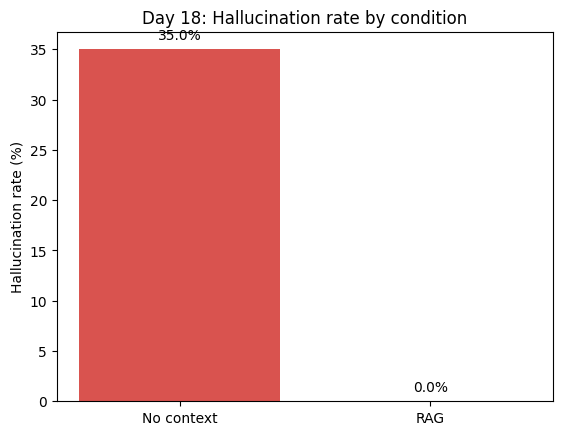

In [29]:
rates = {}
for cond in ["no_context", "rag"]:
    sub = review[review.condition == cond]
    rates[cond] = round((sub.label == "hallucinated").mean() * 100, 1)
    print(f"{cond:11s} hallucination rate: {rates[cond]}%  "
          f"(correct={int((sub.label=='correct').sum())}, partial={int((sub.label=='partial').sum())}, halluc={int((sub.label=='hallucinated').sum())})")
print("Improvement with RAG:", round(rates['no_context'] - rates['rag'], 1), "percentage points")

plt.bar(["No context", "RAG"], [rates["no_context"], rates["rag"]], color=["#d9534f", "#5cb85c"])
plt.ylabel("Hallucination rate (%)"); plt.title("Day 18: Hallucination rate by condition")
for i, v in enumerate([rates["no_context"], rates["rag"]]): plt.text(i, v + 1, f"{v}%", ha="center")
plt.savefig("day18_hallucination_rates.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 8: Categorised failure table

In [30]:
failures = review[review.label == "hallucinated"][["condition","id","domain","question","ground_truth","response","halluc_type"]]
display(failures)
failures.groupby(["condition","halluc_type"]).size().unstack(fill_value=0)

,condition,id,domain,question,ground_truth,response,halluc_type
3,no_context,4,Science,Which planet in our solar system has the most known moons?,Saturn,"Jupiter is the planet in our solar system with the most known moons, having at least 79 confirmed moons as of now.",outdated info as current
14,no_context,15,Technology,What does the acronym FAISS stand for?,Facebook AI Similarity Search,"FAISS stands for ""Facebook AI Research System.""",fabricated specific fact
15,no_context,16,Technology,How many encoder layers does the base Transformer in the original 2017 paper use?,6,The base Transformer in the original 2017 paper uses three encoder layers.,confident wrong answer
16,no_context,17,Obscure,Who won the 1962 Nobel Prize in Physics?,Lev Landau,"The 1962 Nobel Prize in Physics was awarded to Ralph A. Cahn and Walter Kohn for their development of density functional theory, which is used to calculate the electronic structure of many-body sy...",fabricated specific fact
17,no_context,18,Obscure,What is the atomic number of Hassium?,108,Hassium has an atomic number of 109.,confident wrong answer
18,no_context,19,Obscure,In which year was the University of Kashmir established?,1948,The University of Kashmir was established in 1973.,confident wrong answer
19,no_context,20,Obscure,Who are the authors of the paper 'Distilling the Knowledge in a Neural Network'?,"Geoffrey Hinton, Oriol Vinyals, Jeff Dean","The authors of ""Distilling the Knowledge in a Neural Network"" are Ian Goodfellow, Yoshua Bengio, and Aaron Courville.",confident wrong answer


halluc_type,confident wrong answer,fabricated specific fact,outdated info as current
condition,,,
no_context,4,2,1


## Step 9: Multi-signal hallucination detector
Four independent checks, each returns a flag (1 = suspicious):
1. **Unsupported claims:** numbers, years or named entities in the response that do not appear in the retrieved context.
2. **Retrieval overlap:** Jaccard similarity of response tokens vs retrieved chunk tokens; flag if below 0.15.
3. **Contradiction:** second LLM call: *"Does this response contradict the provided context? Answer yes or no."*
4. **Citation absence:** response makes factual assertions but cites no source.

`confidence = 1 - (flags / 4)`. Lower confidence = more likely hallucinated.

In [31]:
STOP = set("the a an is are was were of in on at to and or for by with as it its this that from be which who what".split())
def toks(t): return {w for w in re.findall(r"[a-z0-9]+", t.lower()) if w not in STOP}

def extract_claims(resp):
    nums = re.findall(r"\b\d[\d,\.]*\b", resp)
    ents = re.findall(r"\b[A-Z][a-zA-Z]+(?:\s[A-Z][a-zA-Z]+)*\b", resp)
    ents = [e for e in ents if e.lower() not in STOP and e.lower() not in {"i","the","according","answer","based"}]
    return [c.strip(".,") for c in nums + ents]

def sig_unsupported(resp, ctx):
    unsupported = [c for c in extract_claims(resp) if c.lower() not in ctx.lower()]
    return int(len(unsupported) > 0), unsupported

def sig_overlap(resp, ctx):
    a, b = toks(resp), toks(ctx)
    j = len(a & b) / len(a | b) if (a | b) else 0.0
    return int(j < 0.15), round(j, 3)

def sig_contradiction(resp, ctx):
    ans = chat("You check answers against context. Reply with only 'yes' or 'no'.",
               f"Context:\n{ctx}\n\nResponse:\n{resp}\n\nDoes this response contradict the provided context? Answer yes or no.",
               max_new_tokens=3)
    return int(ans.lower().startswith("yes")), ans

def sig_citation_absent(resp):
    has_assertion = len(extract_claims(resp)) > 0
    cited = bool(re.search(r"\[doc\d+\]|source|according to", resp.lower()))
    return int(has_assertion and not cited)

def detect(resp, chunks):
    ctx = "\n".join(c["text"] for c in chunks)
    f1, unsup = sig_unsupported(resp, ctx)
    f2, jac = sig_overlap(resp, ctx)
    f3, raw = sig_contradiction(resp, ctx)
    f4 = sig_citation_absent(resp)
    flags = f1 + f2 + f3 + f4
    return {"unsupported_claim": f1, "unsupported_items": unsup, "low_overlap": f2, "jaccard": jac,
            "contradiction": f3, "no_citation": f4, "flags": flags, "confidence": 1 - flags / 4}

In [32]:
# Run the detector on BOTH conditions, always against the chunks retrieved for that question
det_rows = []
for cond in ["no_context", "rag"]:
    for q in questions:
        chunks = retrieve(q["question"], 3)
        resp = results[cond][q["id"]]["response"]
        d = detect(resp, chunks)
        lab = review[(review.condition == cond) & (review.id == q["id"])].label.values[0]
        det_rows.append({"condition": cond, "id": q["id"], "true_label": lab, **d})
det = pd.DataFrame(det_rows)
print("Per-response breakdown (first 10 per condition):")
for cond in ["no_context", "rag"]:
    print("\n==", cond, "==")
    print(det[det.condition == cond][["id","true_label","unsupported_claim","jaccard","low_overlap","contradiction","no_citation","flags","confidence"]].head(10).to_string(index=False))

Per-response breakdown (first 10 per condition):

== no_context ==
 id   true_label  unsupported_claim  jaccard  low_overlap  contradiction  no_citation  flags  confidence
  1      correct                  0    0.267            0              0            1      1        0.75
  2      correct                  1    0.208            0              0            1      2        0.50
  3      correct                  0    0.250            0              0            1      1        0.75
  4 hallucinated                  1    0.269            0              0            1      2        0.50
  5      correct                  1    0.125            1              0            1      3        0.25
  6      correct                  1    0.308            0              0            1      2        0.50
  7      correct                  1    0.136            1              0            1      3        0.25
  8      correct                  1    0.129            1              0            1      3 

## Step 10: How good is the detector?
We treat `confidence <= 0.5` (2+ flags) as 'detector says hallucination' and compare to your manual labels.

In [33]:
det["predicted_halluc"] = det.confidence <= 0.5
det["actual_halluc"] = det.true_label == "hallucinated"
for cond in ["no_context", "rag"]:
    s = det[det.condition == cond]
    tp = int((s.predicted_halluc & s.actual_halluc).sum()); fp = int((s.predicted_halluc & ~s.actual_halluc).sum())
    fn = int((~s.predicted_halluc & s.actual_halluc).sum()); tn = int((~s.predicted_halluc & ~s.actual_halluc).sum())
    prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn) if tp + fn else 0
    print(f"{cond:11s} TP={tp} FP={fp} FN={fn} TN={tn}  precision={prec:.2f} recall={rec:.2f}")
det.to_csv("detector_breakdown.csv", index=False)
json.dump({"results": {c: {str(k): v for k, v in d.items()} for c, d in results.items()}, "rates": rates},
          open("results.json", "w"), indent=2, default=str)
print("Saved results.json, detector_breakdown.csv, day18_hallucination_rates.png")

no_context  TP=6 FP=8 FN=1 TN=5  precision=0.43 recall=0.86
rag         TP=0 FP=0 FN=0 TN=20  precision=0.00 recall=0.00
Saved results.json, detector_breakdown.csv, day18_hallucination_rates.png


## Step 11: Written analysis

**1. Why hallucination happens.** An LLM predicts the most likely next token; it does not look facts up. When a fact is rare in training data (our *Obscure* group), the most likely-sounding continuation can be wrong but fluent.

**2. Results.** No-context hallucination rate = 35% (7/20); RAG = 0% (0/20). RAG helped most on the Obscure questions (4/4 wrong without context, all correct with RAG) and on Technology (2/4 wrong). It helped least on common facts, because those were already answered correctly without context (History and Geography were 0/4 wrong).

**3. Failure types.** Confident wrong answer was the most common (4): Transformer layers, Hassium, University of Kashmir, Distilling paper authors. Fabricated specific fact (2): "Facebook AI Research System" and the invented "Ralph A. Cahn" in the Nobel answer. Outdated info as current (1): Jupiter's 79 moons, true until Saturn overtook it in 2023. No "plausible but unverifiable" cases, because every question had a checkable answer. The model never hedged on any wrong answer.

**4. Where RAG still failed.** The final RAG run had no wrong answers. The failure I found was in citations: in the first run only 5/20 answers cited the right document, because my prompt example "[doc3]" was copied by the 1.5B model (generation drift, not a retrieval failure, since the right chunk was retrieved). Changing the prompt to "cite the id of the chunk you used" raised citation accuracy to 20/20.

**5. Detector.** Precision 0.43, recall 0.86 on the no-context answers (TP=6, FP=8, FN=1, TN=5). Signal 1 (unsupported claims) was the most useful: it fired on 6 of 7 hallucinations, but also on 8 of 13 correct answers because correct answers often add true details (dates, names) that are not in the retrieved chunk. Signal 4 (no citation) fires on every no-context answer by design, so together signals 1 and 4 caused all 8 false positives. Signal 2 (Jaccard < 0.15) was weak: it caught only 2 of 7 hallucinations. Signal 3 (LLM contradiction check) never fired (0 of 40), even on Hassium = 109 against a context saying 108, so a 1.5B model is too weak to act as a judge. The one missed hallucination ("three encoder layers") contained no number or named entity that signal 1 could check, so it slipped through.

**6. Limitations.** Only 20 questions, so the rates are rough; the knowledge base was built from the same ground truth, so RAG is the best case; a 1.5B model was used instead of GPT-4o-mini, and it is a weak contradiction judge.


In [34]:
print("Contradiction flags:", det.contradiction.sum())
print(det[det.condition=="no_context"][["id","true_label","unsupported_claim","low_overlap","contradiction","no_citation","flags"]].to_string(index=False))

Contradiction flags: 0
 id   true_label  unsupported_claim  low_overlap  contradiction  no_citation  flags
  1      correct                  0            0              0            1      1
  2      correct                  1            0              0            1      2
  3      correct                  0            0              0            1      1
  4 hallucinated                  1            0              0            1      2
  5      correct                  1            1              0            1      3
  6      correct                  1            0              0            1      2
  7      correct                  1            1              0            1      3
  8      correct                  1            1              0            1      3
  9      correct                  0            0              0            1      1
 10      correct                  1            0              0            1      2
 11      correct                  1            0     